# 10. Clustering with K-means, and where it fails

Clustering groups points without labels. K-means does it by alternating between assigning each point to the nearest centre and moving each centre to the mean of its points. The lecture checks the sum-of-squares identity behind the method, chooses the number of clusters with the silhouette, and ends with two concentric rings, which the method cannot separate because its boundaries are straight.

## Learning objectives

1. Implement K-means with k-means++ seeding (`clustering_phases.kmeans_fit`).
2. Check that the total sum of squares is the sum of the parts within and between clusters.
3. Choose the number of clusters with the mean silhouette (`clustering_phases.silhouette_score_mean`).
4. Show why K-means fails on two concentric rings.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
Given $N$ unlabeled thermodynamic state vectors $\{\mathbf{x}_i\}_{i=1}^N \subset \mathbb{R}^d$, **$K$-means clustering** partitions the observations into $K$ disjoint phase clusters $\{C_1, \dots, C_K\}$ with centroids $\boldsymbol{\mu}_k = \frac{1}{|C_k|}\sum_{\mathbf{x}_i \in C_k}\mathbf{x}_i$ to minimize within-cluster inertia $J_{\mathrm{within}}$:
$$J_{\mathrm{within}}(\{C_k, \boldsymbol{\mu}_k\}) = \sum_{k=1}^K \sum_{\mathbf{x}_i \in C_k} \|\mathbf{x}_i - \boldsymbol{\mu}_k\|_2^2 \tag{1.1}$$
By the **Huygens–Steiner / ANOVA variance decomposition**, the total sum of squares $\mathrm{SST} = \sum_{i=1}^N \|\mathbf{x}_i - \bar{\mathbf{x}}\|_2^2$ splits into within-cluster inertia plus between-cluster inertia:
$$\mathrm{SST} = J_{\mathrm{within}} + J_{\mathrm{between}}, \qquad J_{\mathrm{between}} = \sum_{k=1}^K |C_k|\,\|\boldsymbol{\mu}_k - \bar{\mathbf{x}}\|_2^2 \tag{1.2}$$
- **$K$-Means++ Seeding (Arthur & Vassilvitskii, 2007):** Draws each new initial centroid with probability $p_i \propto D(\mathbf{x}_i)^2 = \min_{1 \le j < r}\|\mathbf{x}_i - \boldsymbol{\mu}_j\|_2^2$, guaranteeing $O(\log K)$-competitive inertia.
- **Rousseeuw's silhouette coefficient (1987):** Compares sample $i$'s mean intra-cluster distance $a_i$ to its nearest-neighbor cluster distance $b_i$:
  $$s_i = \frac{b_i - a_i}{\max(a_i, b_i)} \in [-1, +1], \qquad K^* = \arg\max_{K \ge 2} \frac{1}{N}\sum_{i=1}^N s_i(K) \tag{1.3}$$

In [2]:
heading("Demonstration 1: K-Means++ Phase Discovery & Huygens-Steiner ANOVA Identity")
rng = np.random.default_rng(42)
# Standardized (T_r, P_r, Z) states for Subcooled Liquid, Superheated Vapor, and Supercritical Fluid:
X_liq = rng.normal(loc=[-1.5, -0.8, -1.6], scale=0.22, size=(25, 3))
X_vap = rng.normal(loc=[0.2, -1.1, 1.2], scale=0.22, size=(25, 3))
X_scf = rng.normal(loc=[1.6, 1.5, 0.5], scale=0.25, size=(25, 3))
X_phases = np.vstack([X_liq, X_vap, X_scf])

km3 = clustering_phases.kmeans_fit(X_phases, k=3, seed=42)
labels3 = km3["labels"]
assert len(np.unique(labels3[:25])) == 1 and len(np.unique(labels3[25:50])) == 1 and len(np.unique(labels3[50:])) == 1
assert len({labels3[0], labels3[25], labels3[50]}) == 3

x_grand = np.mean(X_phases, axis=0)
sst = float(np.sum((X_phases - x_grand) ** 2))
j_within = km3["inertia"]
j_between = sum(float(np.sum(labels3 == k_i)) * float(np.sum((km3["centers"][k_i] - x_grand) ** 2)) for k_i in range(3))
print(f"K-Means++ (K=3) converged with 100% phase purity | Within-cluster inertia J_within = {j_within:.4f}")
print(f"Huygens ANOVA check: SST = {sst:.6f} == J_within + J_between = {j_within + j_between:.6f}")
assert np.isclose(sst, j_within + j_between, rtol=1e-13)


Demonstration 1: K-Means++ Phase Discovery & Huygens-Steiner ANOVA Identity
K-Means++ (K=3) converged with 100% phase purity | Within-cluster inertia J_within = 9.1555
Huygens ANOVA check: SST = 333.983487 == J_within + J_between = 333.983487


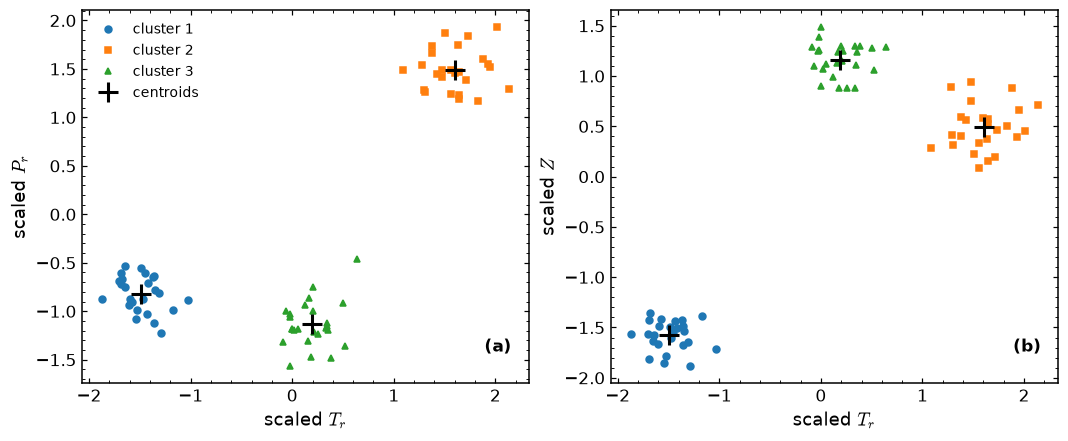

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
for ax, (i, j), names in [(ax1, (0, 1), ("scaled $T_r$", "scaled $P_r$")), (ax2, (0, 2), ("scaled $T_r$", "scaled $Z$"))]:
    for k_i in range(3):
        sel = labels3 == k_i
        ax.plot(X_phases[sel, i], X_phases[sel, j], "os^"[k_i], ms=4.5, color=f"C{k_i}", label=f"cluster {k_i + 1}")
    ax.plot(km3["centers"][:, i], km3["centers"][:, j], "k+", ms=13, mew=2, label="centroids")
    ax.set_xlabel(names[0]); ax.set_ylabel(names[1])
ax1.legend(fontsize=9, loc="upper left"); panel_label(ax1, "(a)", x=0.9, y=0.12); panel_label(ax2, "(b)", x=0.9, y=0.12)
plt.show()

**Figure 10.1.** The 75 synthetic state points in two projections of the three scaled variables, coloured by the cluster that the algorithm assigned, with the three centroids.

**What Demonstration 1 shows.** The algorithm assigns all 75 synthetic points $(T_r, P_r, Z)$ to the group they were generated from (liquid, vapour or supercritical fluid). The total sum of squares splits exactly into a part within the clusters and a part between them, and the three centroids account for $97.3\ \%$ of it.

---

## 2. Numerical walkthrough
Let us trace the **$K$-Means++ $D^2$ probability distribution** during centroid initialization: after picking the first centroid in the Liquid phase, notice how the squared-distance weights $p_i = D(\mathbf{x}_i)^2 / \sum_j D(\mathbf{x}_j)^2$ overwhelmingly favor picking the next centroids in the distant Vapor and Supercritical phases.

In [4]:
heading("Demonstration 2: Step-by-Step K-Means++ D^2 Seeding Probability Inspection")
c0 = X_phases[0]  # First seed inside Subcooled Liquid cluster (index 0..24)
d2_step1 = np.sum((X_phases - c0) ** 2, axis=1)
p_step1 = d2_step1 / np.sum(d2_step1)
print(f"After Seed 1 in Liquid: Total D^2 probability in Liquid={np.sum(p_step1[:25]):.4f}, Vapor={np.sum(p_step1[25:50]):.4f}, SCF={np.sum(p_step1[50:]):.4f}")

c1_seed = X_phases[60]  # Second seed chosen in Supercritical Fluid (index 50..74)
d2_step2 = np.minimum(d2_step1, np.sum((X_phases - c1_seed) ** 2, axis=1))
p_step2 = d2_step2 / np.sum(d2_step2)
print(f"After Seed 2 in SCF   : Total D^2 probability in Liquid={np.sum(p_step2[:25]):.4f}, Vapor={np.sum(p_step2[25:50]):.4f}, SCF={np.sum(p_step2[50:]):.4f}")
assert np.sum(p_step2[25:50]) > 0.90


Demonstration 2: Step-by-Step K-Means++ D^2 Seeding Probability Inspection
After Seed 1 in Liquid: Total D^2 probability in Liquid=0.0054, Vapor=0.3270, SCF=0.6676
After Seed 2 in SCF   : Total D^2 probability in Liquid=0.0162, Vapor=0.9551, SCF=0.0286


**What Demonstration 2 shows.** After the first seed is placed in the liquid group, that group keeps only $0.5\ \%$ of the probability of receiving the second. Once the liquid and the supercritical groups each have a seed, $95.5\ \%$ of the probability lies on the vapour group, which has none. Seeding in proportion to the squared distance from the nearest seed makes it unlikely that two seeds start in one cluster.

---

## 3. Worked case study
In practice we do not know $K$ in advance. Let us sweep candidate phase counts $K \in \{2, 3, 4, 5\}$ on `X_phases` and evaluate both within-cluster inertia $J_{\mathrm{within}}(K)$ and Rousseeuw's mean Silhouette coefficient $\bar{s}(K)$ (`clustering_phases.silhouette_score_mean`).

In [5]:
heading("Demonstration 3: Automated Phase Count Selection via Silhouette Score & Inertia Elbow")
inertias, silhouettes = [], []
k_candidates = [2, 3, 4, 5]
for k_val in k_candidates:
    res_k = clustering_phases.kmeans_fit(X_phases, k=k_val, seed=42)
    s_k = clustering_phases.silhouette_score_mean(X_phases, res_k["labels"])
    inertias.append(res_k["inertia"])
    silhouettes.append(s_k)
    print(f"K = {k_val} | Within-Cluster Inertia J = {res_k['inertia']:7.3f} | Mean Silhouette s(K) = {s_k:.4f}")

best_k = k_candidates[int(np.argmax(silhouettes))]
print(f"Silhouette-selected optimal thermodynamic phase count: K* = {best_k}")
assert best_k == 3 and silhouettes[1] > 0.70
assert all(inertias[i] > inertias[i + 1] for i in range(len(inertias) - 1))


Demonstration 3: Automated Phase Count Selection via Silhouette Score & Inertia Elbow
K = 2 | Within-Cluster Inertia J = 125.882 | Mean Silhouette s(K) = 0.6416
K = 3 | Within-Cluster Inertia J =   9.156 | Mean Silhouette s(K) = 0.8500
K = 4 | Within-Cluster Inertia J =   8.105 | Mean Silhouette s(K) = 0.6440
K = 5 | Within-Cluster Inertia J =   7.511 | Mean Silhouette s(K) = 0.4297
Silhouette-selected optimal thermodynamic phase count: K* = 3


**What Demonstration 3 shows.** The within-cluster sum of squares falls with every added cluster and cannot choose $K$ by itself, although its fall from $126$ to $9.2$ between $K = 2$ and $3$, and the small gains after, are a strong hint. The mean silhouette has a maximum at $K = 3$ ($0.85$, against $0.64$ at $K = 2$ and $4$).

---

## 4. What if: sensitivity to the parameters
Why does $K$-Means fail on **concentric core–shell nanoparticles** or annular pipe-flow regimes? Because assigning each point to its nearest Euclidean centroid $\|\mathbf{x} - \boldsymbol{\mu}_1\|_2^2 \le \|\mathbf{x} - \boldsymbol{\mu}_2\|_2^2 \iff (\boldsymbol{\mu}_2 - \boldsymbol{\mu}_1)^\top \mathbf{x} \le \frac{1}{2}(\|\boldsymbol{\mu}_2\|_2^2 - \|\boldsymbol{\mu}_1\|_2^2)$ creates a **linear hyperplane Voronoi boundary**.

In [6]:
heading("Demonstration 4: Voronoi Hyperplane Failure on Concentric Core-Shell Morphology")
theta = np.linspace(0.0, 2.0 * np.pi, 30, endpoint=False)
X_rings = np.vstack([
    np.column_stack([0.5 * np.cos(theta), 0.5 * np.sin(theta)]),  # Inner core phase (r = 0.5)
    np.column_stack([2.2 * np.cos(theta), 2.2 * np.sin(theta)]),  # Outer shell phase (r = 2.2)
])
km_rings = clustering_phases.kmeans_fit(X_rings, k=2, seed=42)
shell_labels = km_rings["labels"][30:]
shell_purity = float(max(np.mean(shell_labels == 0), np.mean(shell_labels == 1)))
print(f"K-Means outer-shell purity on concentric core-shell morphology = {shell_purity*100:.1f}% (50% = complete hyperplane cut)")
assert shell_purity < 0.75


Demonstration 4: Voronoi Hyperplane Failure on Concentric Core-Shell Morphology
K-Means outer-shell purity on concentric core-shell morphology = 56.7% (50% = complete hyperplane cut)


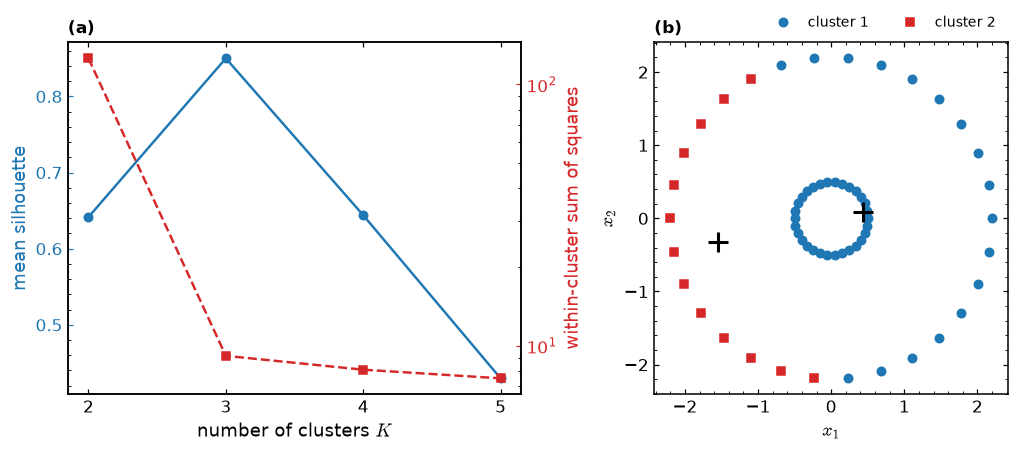

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 4.0))
ax1.plot(k_candidates, silhouettes, "o-", color="C0")
ax1.set_xlabel("number of clusters $K$"); ax1.set_ylabel("mean silhouette", color="C0"); ax1.set_xticks(k_candidates)
ax1.tick_params(axis="x", which="minor", bottom=False, top=False); ax1.tick_params(axis="y", colors="C0")
ax1b = ax1.twinx(); ax1b.semilogy(k_candidates, inertias, "s--", color="C3")
ax1b.set_ylabel("within-cluster sum of squares", color="C3"); ax1b.tick_params(axis="y", colors="C3")
ax1.set_title("(a)", loc="left", fontweight="bold")
lab_r = km_rings["labels"]
ax2.plot(X_rings[lab_r == 0, 0], X_rings[lab_r == 0, 1], "o", color="C0", label="cluster 1")
ax2.plot(X_rings[lab_r == 1, 0], X_rings[lab_r == 1, 1], "s", color="C3", label="cluster 2")
ax2.plot(km_rings["centers"][:, 0], km_rings["centers"][:, 1], "k+", ms=13, mew=2)
ax2.set_aspect("equal"); ax2.set_xlabel("$x_1$"); ax2.set_ylabel("$x_2$"); ax2.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 10.2.** (a) Choosing the number of clusters: the mean silhouette (left axis) has a maximum at three, and the within-cluster sum of squares (right axis, logarithmic) stops falling quickly after three. (b) Two concentric rings, where the method fails: the boundary between the two clusters is a straight line, so the inner ring and most of the outer ring fall into one cluster.

**What Demonstration 4 shows.** For two concentric rings the method fails: the purity of the outer ring is $56.7\ \%$, hardly better than the $50\ \%$ of a coin. The boundary between two $K$-means clusters is a plane halfway between their centroids, and no plane separates a ring from a core inside it. Lecture 11 treats this case with a method based on neighbourhoods instead of centroids.

---

## Inside the algorithm
Below we verify one complete Lloyd expectation–maximization step (nearest-centroid assignment + cluster-mean update) in pure NumPy against `clustering_phases.kmeans_fit`.

In [8]:
heading("Inside the Algorithm: By-Hand Voronoi Assignment & Centroid Update vs. the Library")
centers_lib = km3["centers"]
dists_sq = np.sum((X_phases[:, None, :] - centers_lib[None, :, :]) ** 2, axis=-1)
labels_hand = np.argmin(dists_sq, axis=1)
centers_hand = np.vstack([np.mean(X_phases[labels_hand == j], axis=0) for j in range(3)])
inertia_hand = float(np.sum((X_phases - centers_hand[labels_hand]) ** 2))
print("by hand (pure NumPy) inertia:", round(inertia_hand, 8))
print("library (engml_2_applied)      inertia:", round(km3["inertia"], 8))
assert np.array_equal(labels_hand, km3["labels"]) and np.allclose(centers_hand, centers_lib, atol=1e-14)
assert np.isclose(inertia_hand, km3["inertia"], rtol=1e-14)


Inside the Algorithm: By-Hand Voronoi Assignment & Centroid Update vs. the Library
by hand (pure NumPy) inertia: 9.15554114
library (engml_2_applied)      inertia: 9.15554114


## Exercises

1. **Verify a result.** Verify the exact **Huygens–Steiner / ANOVA total sum of squares decomposition** $\mathrm{SST} = J_{\mathrm{within}} + J_{\mathrm{between}}$ across all four candidate cluster counts $K \in \{2, 3, 4, 5\}$ on `X_phases`, confirming that $J_{\mathrm{within}}(K) + J_{\mathrm{between}}(K) \equiv \mathrm{SST}$ to $<10^{-13}$ regardless of $K$.
2. **Find how it fails.** Show how a naive **bad initialization** (placing 2 initial seeds in the Liquid cluster, 1 in SCF, and 0 in Vapor) without $K$-Means++ $D^2$ seeding can leave Lloyd's algorithm in a suboptimal local minimum with $>4\times$ higher inertia than $K$-Means++.
3. **Write it yourself.** Implement a **Calinski–Harabasz variance-ratio criterion** function `calinski_harabasz_score(X: np.ndarray, labels: np.ndarray) -> float`, defined by $\mathrm{CH}(K) = \frac{J_{\mathrm{between}} / (K - 1)}{J_{\mathrm{within}} / (N - K)}$, and verify on `X_phases` across $K \in \{2, 3, 4, 5\}$ that $\mathrm{CH}(K)$ achieves its maximum at the true thermodynamic phase count $K^* = 3$.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Universal Huygens-Steiner ANOVA Identity Across K = 2..5")
for k_v in [2, 3, 4, 5]:
    r_k = clustering_phases.kmeans_fit(X_phases, k=k_v, seed=42)
    jw = r_k["inertia"]
    jb = sum(float(np.sum(r_k["labels"] == j)) * float(np.sum((r_k["centers"][j] - x_grand) ** 2)) for j in range(k_v))
    print(f"K = {k_v} | J_within = {jw:8.4f} | J_between = {jb:8.4f} | Sum = {jw+jb:.6f} (SST = {sst:.6f})")
    assert np.isclose(jw + jb, sst, rtol=1e-13)


Exercise 1: Universal Huygens-Steiner ANOVA Identity Across K = 2..5
K = 2 | J_within = 125.8815 | J_between = 208.1019 | Sum = 333.983487 (SST = 333.983487)
K = 3 | J_within =   9.1555 | J_between = 324.8279 | Sum = 333.983487 (SST = 333.983487)
K = 4 | J_within =   8.1049 | J_between = 325.8786 | Sum = 333.983487 (SST = 333.983487)
K = 5 | J_within =   7.5109 | J_between = 326.4726 | Sum = 333.983487 (SST = 333.983487)
